<a href="https://colab.research.google.com/github/williwiser/thesis_structured_pruning/blob/main/thesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCF-Crime: VideoMAE-Small + RTFM + Structured MLP Pruning

This notebook implements the revised thesis pipeline using **only VideoMAE-Small**.

**Pipeline**

UCF-Crime frames → reconstruct videos → temporal snippets → VideoMAE-Small feature extractor → RTFM-style head training → dense baseline → Taylor-based MLP neuron importance → physical structured pruning → recovery fine-tuning → dense/pruned/recovered evaluation.

Taylor importance is the primary pruning criterion. L2 weight importance is implemented as a backup.

The notebook intentionally contains **no VideoMAE-Large, teacher model, knowledge distillation, or student model terminology**.

## 0. Experiment configuration

Start with `smoke_test = True` to verify data grouping, tensor shapes, RTFM training, Taylor gradients, and pruning. Set it to `False` for the full experiment.

In [ ]:
#!pip -q install "transformers>=4.46,<5" accelerate kagglehub pandas scikit-learn pillow tqdm matplotlib safetensors

In [ ]:
import gc
import json
import math
import os
import random
import re
import tempfile
import time
from collections import defaultdict
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import Any

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModelForVideoClassification

@dataclass
class Config:
    seed: int = 42

    # Data
    dataset_slug: str = "odins0n/ucf-crime-dataset"
    validation_fraction: float = 0.15
    extracted_frame_stride: int = 10

    # VideoMAE input
    clip_length: int = 16
    num_snippets: int = 32
    feature_clip_batch: int = 2

    # Single backbone + RTFM head
    videomae_model: str = "MCG-NJU/videomae-small-finetuned-kinetics"
    rtfm_dim: int = 512
    rtfm_top_k: int = 3
    rtfm_dropout: float = 0.5
    rtfm_heads: int = 8

    # RTFM head training on cached VideoMAE features
    head_batch_size: int = 8
    head_epochs: int = 30
    head_lr: float = 1e-4
    weight_decay: float = 1e-4

    # Taylor importance
    importance_method: str = "taylor"   # "taylor" or "l2"
    taylor_batches: int = 50
    taylor_snippets_per_bag: int = 8

    # Structured pruning
    prune_ratio: float = 0.75
    prune_multiple: int = 8

    # Recovery fine-tuning
    recovery_snippets_per_bag: int = 8
    recovery_epochs: int = 3
    recovery_backbone_lr: float = 2e-6
    recovery_head_lr: float = 1e-4
    recovery_unfreeze_last_blocks: int = 2
    accumulation_steps: int = 4

    # Runtime / debugging
    smoke_test: bool = False
    smoke_train_videos: int = 32
    smoke_val_videos: int = 16
    smoke_test_videos: int = 16
    use_google_drive: bool = False
    work_dir: str = "/content/ucfcrime_videomae_rtfm_small"

CFG = Config()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

if CFG.use_google_drive:
    from google.colab import drive
    drive.mount("/content/drive")
    CFG.work_dir = "/content/drive/MyDrive/ucfcrime_videomae_rtfm_small"

WORK_DIR = Path(CFG.work_dir)
MANIFEST_DIR = WORK_DIR / "manifests"
FEATURE_DIR = WORK_DIR / "features"
CHECKPOINT_DIR = WORK_DIR / "checkpoints"
RESULT_DIR = WORK_DIR / "results"
IMPORTANCE_DIR = WORK_DIR / "importance"
for directory in [WORK_DIR, MANIFEST_DIR, FEATURE_DIR, CHECKPOINT_DIR, RESULT_DIR, IMPORTANCE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(CFG.seed)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print(json.dumps(asdict(CFG), indent=2))

Device: cuda
GPU: Tesla T4
{
  "seed": 42,
  "dataset_slug": "odins0n/ucf-crime-dataset",
  "validation_fraction": 0.15,
  "extracted_frame_stride": 10,
  "clip_length": 16,
  "num_snippets": 32,
  "feature_clip_batch": 2,
  "videomae_model": "MCG-NJU/videomae-small-finetuned-kinetics",
  "rtfm_dim": 512,
  "rtfm_top_k": 3,
  "rtfm_dropout": 0.5,
  "rtfm_heads": 8,
  "head_batch_size": 8,
  "head_epochs": 30,
  "head_lr": 0.0001,
  "weight_decay": 0.0001,
  "importance_method": "taylor",
  "taylor_batches": 50,
  "taylor_snippets_per_bag": 8,
  "prune_ratio": 0.75,
  "prune_multiple": 8,
  "recovery_snippets_per_bag": 8,
  "recovery_epochs": 3,
  "recovery_backbone_lr": 2e-06,
  "recovery_head_lr": 0.0001,
  "recovery_unfreeze_last_blocks": 2,
  "accumulation_steps": 4,
  "smoke_test": false,
  "smoke_train_videos": 32,
  "smoke_val_videos": 16,
  "smoke_test_videos": 16,
  "use_google_drive": false,
  "work_dir": "/content/ucfcrime_videomae_rtfm_small"
}


## 1. Download and locate the UCF-Crime frame dataset

The Kaggle derivative stores retained frames in class folders. The notebook reconstructs source-video boundaries from frame filenames so each RTFM bag corresponds to one original video.

In [ ]:
DATASET_DOWNLOAD = Path(kagglehub.dataset_download(CFG.dataset_slug))
print("Downloaded/cached at:", DATASET_DOWNLOAD)

def locate_train_test_root(root: Path) -> tuple[Path, Path]:
    candidates = []
    for train_dir in root.rglob("Train"):
        test_dir = train_dir.parent / "Test"
        if train_dir.is_dir() and test_dir.is_dir():
            candidates.append((train_dir, test_dir))
    if not candidates:
        raise FileNotFoundError(
            f"Could not find sibling Train and Test directories under {root}."
        )
    candidates.sort(
        key=lambda pair: len([p for p in pair[0].iterdir() if p.is_dir()]),
        reverse=True,
    )
    return candidates[0]

TRAIN_FRAME_ROOT = DATASET_DOWNLOAD / "Train"   # adjust to the actual discovered depth
TEST_FRAME_ROOT = DATASET_DOWNLOAD / "Test"

if not (TRAIN_FRAME_ROOT.is_dir() and TEST_FRAME_ROOT.is_dir()):
    # Fallback to the slow-but-safe search only if the direct path is wrong
    TRAIN_FRAME_ROOT, TEST_FRAME_ROOT = locate_train_test_root(DATASET_DOWNLOAD)

print("Train root:", TRAIN_FRAME_ROOT)
print("Test root :", TEST_FRAME_ROOT)
print("Train classes:", sorted(p.name for p in TRAIN_FRAME_ROOT.iterdir() if p.is_dir()))

Downloaded/cached at: /root/.cache/kagglehub/datasets/odins0n/ucf-crime-dataset/versions/1
Train root: /root/.cache/kagglehub/datasets/odins0n/ucf-crime-dataset/versions/1/Train
Test root : /root/.cache/kagglehub/datasets/odins0n/ucf-crime-dataset/versions/1/Test
Train classes: ['Abuse', 'Arrest', 'Arson', 'Assault', 'Burglary', 'Explosion', 'Fighting', 'NormalVideos', 'RoadAccidents', 'Robbery', 'Shooting', 'Shoplifting', 'Stealing', 'Vandalism']


## 2. Reconstruct original videos from frame filenames

In [ ]:
PNG_SUFFIXES = {".png", ".jpg", ".jpeg"}

def is_normal_category(category: str) -> bool:
    normalized = re.sub(r"[^a-z]", "", category.lower())
    return normalized.startswith("normal")

def parse_video_id_and_frame_index(path: Path) -> tuple[str, int]:
    stem = path.stem
    match = re.match(r"^(.*)_([0-9]+)$", stem)
    if match:
        return match.group(1), int(match.group(2))
    return stem, 0

def build_manifest(split_root: Path, split_name: str) -> pd.DataFrame:
    grouped: dict[tuple[str, str], list[tuple[int, str]]] = defaultdict(list)
    class_dirs = sorted(p for p in split_root.iterdir() if p.is_dir())
    for class_dir in tqdm(class_dirs, desc=f"Scanning {split_name} classes"):
        category = class_dir.name
        for entry in os.scandir(class_dir):
            if not entry.is_file():
                continue
            path = Path(entry.path)
            if path.suffix.lower() not in PNG_SUFFIXES:
                continue
            video_id, frame_index = parse_video_id_and_frame_index(path)
            grouped[(category, video_id)].append((frame_index, str(path)))

    rows = []
    for (category, video_id), indexed_paths in tqdm(grouped.items(), desc=f"Sorting {split_name} videos"):
        indexed_paths.sort(key=lambda pair: pair[0])
        frame_indices = [pair[0] for pair in indexed_paths]
        frame_paths = [pair[1] for pair in indexed_paths]
        rows.append({
            "source_split": split_name,
            "category": category,
            "video_id": video_id,
            "key": f"{category}__{video_id}",
            "label": 0 if is_normal_category(category) else 1,
            "num_frames": len(frame_paths),
            "frame_indices": frame_indices,
            "frame_paths": frame_paths,
        })

    manifest = pd.DataFrame(rows).sort_values(["label", "category", "video_id"]).reset_index(drop=True)
    if manifest.empty:
        raise RuntimeError(f"No videos were reconstructed from {split_root}")
    if manifest["key"].duplicated().any():
        raise RuntimeError("Duplicate reconstructed video keys found.")
    return manifest

train_manifest_cache = MANIFEST_DIR / "kaggle_train_manifest.pkl"
test_manifest_cache = MANIFEST_DIR / "kaggle_test_manifest.pkl"
if train_manifest_cache.exists() and test_manifest_cache.exists():
    full_train_manifest = pd.read_pickle(train_manifest_cache)
    full_test_manifest = pd.read_pickle(test_manifest_cache)
    print("Loaded cached manifests.")
else:
    full_train_manifest = build_manifest(TRAIN_FRAME_ROOT, "train")
    full_test_manifest = build_manifest(TEST_FRAME_ROOT, "test")
    full_train_manifest.to_pickle(train_manifest_cache)
    full_test_manifest.to_pickle(test_manifest_cache)

print("Reconstructed train videos:", len(full_train_manifest))
print("Reconstructed test videos :", len(full_test_manifest))
print("\nTrain label counts:")
print(full_train_manifest.groupby(["label", "category"]).size())
print("\nTest label counts:")
print(full_test_manifest.groupby(["label", "category"]).size())

Loaded cached manifests.
Reconstructed train videos: 1610
Reconstructed test videos : 290

Train label counts:
label  category     
0      NormalVideos     800
1      Abuse             48
       Arrest            45
       Arson             41
       Assault           47
       Burglary          87
       Explosion         29
       Fighting          45
       RoadAccidents    127
       Robbery          145
       Shooting          27
       Shoplifting       29
       Stealing          95
       Vandalism         45
dtype: int64

Test label counts:
label  category     
0      NormalVideos     150
1      Abuse              2
       Arrest             5
       Arson              9
       Assault            3
       Burglary          13
       Explosion         21
       Fighting           5
       RoadAccidents     23
       Robbery            5
       Shooting          23
       Shoplifting       21
       Stealing           5
       Vandalism          5
dtype: int64


## 3. Validate video reconstruction and create train/validation/test splits

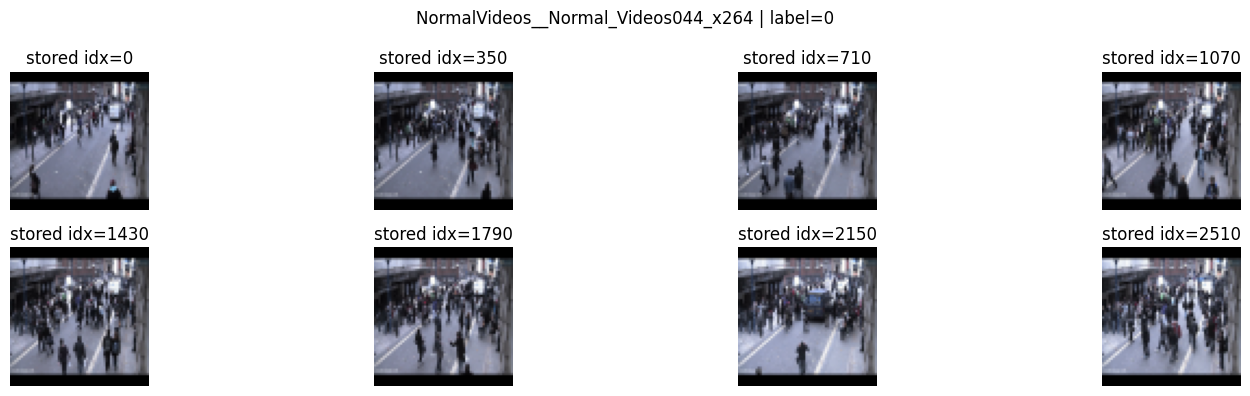

train     : 1368 videos | labels {1: 688, 0: 680}
validation:  242 videos | labels {1: 122, 0: 120}
test      :  290 videos | labels {0: 150, 1: 140}


In [ ]:
def show_video_frames(row: pd.Series, count: int = 8) -> None:
    positions = np.linspace(0, row["num_frames"] - 1, num=min(count, row["num_frames"]), dtype=int)
    plt.figure(figsize=(16, 4))
    cols = math.ceil(len(positions) / 2)
    for plot_index, frame_position in enumerate(positions, start=1):
        with Image.open(row["frame_paths"][frame_position]) as image:
            image = image.convert("RGB")
        ax = plt.subplot(2, cols, plot_index)
        ax.imshow(image)
        ax.set_title(f"stored idx={row['frame_indices'][frame_position]}")
        ax.axis("off")
    plt.suptitle(f"{row['key']} | label={row['label']}")
    plt.tight_layout()
    plt.show()

show_video_frames(full_train_manifest.sample(1, random_state=CFG.seed).iloc[0])

train_indices, val_indices = train_test_split(
    np.arange(len(full_train_manifest)),
    test_size=CFG.validation_fraction,
    random_state=CFG.seed,
    stratify=full_train_manifest["label"],
)

train_manifest = full_train_manifest.iloc[train_indices].reset_index(drop=True)
val_manifest = full_train_manifest.iloc[val_indices].reset_index(drop=True)
test_manifest = full_test_manifest.copy().reset_index(drop=True)

def balanced_limit(df: pd.DataFrame, maximum: int, seed: int) -> pd.DataFrame:
    if len(df) <= maximum:
        return df.reset_index(drop=True)
    parts = []
    labels = sorted(df["label"].unique())
    per_label = max(1, maximum // len(labels))
    for label in labels:
        subset = df[df["label"] == label]
        take = min(per_label, len(subset))
        parts.append(subset.sample(take, random_state=seed + int(label)))
    result = pd.concat(parts, ignore_index=True)
    if len(result) < maximum:
        remaining = df[~df["key"].isin(result["key"])]
        extra = remaining.sample(min(maximum - len(result), len(remaining)), random_state=seed + 100)
        result = pd.concat([result, extra], ignore_index=True)
    return result.sample(frac=1, random_state=seed).reset_index(drop=True)

if CFG.smoke_test:
    train_manifest = balanced_limit(train_manifest, CFG.smoke_train_videos, CFG.seed)
    val_manifest = balanced_limit(val_manifest, CFG.smoke_val_videos, CFG.seed + 1)
    test_manifest = balanced_limit(test_manifest, CFG.smoke_test_videos, CFG.seed + 2)
    CFG.num_snippets = 8

for name, manifest in [("train", train_manifest), ("validation", val_manifest), ("test", test_manifest)]:
    print(f"{name:10s}: {len(manifest):4d} videos | labels {manifest['label'].value_counts().to_dict()}")

## 4. Build deterministic temporal snippets

Each video is represented by `num_snippets` evenly spaced temporal positions. Each snippet contains 16 retained frames.

In [ ]:
def uniform_snippet_starts(num_frames: int, num_snippets: int, clip_length: int) -> np.ndarray:
    max_start = max(0, num_frames - clip_length)
    if num_snippets == 1:
        return np.array([max_start // 2], dtype=np.int64)
    return np.rint(np.linspace(0, max_start, num=num_snippets)).astype(np.int64)

def infer_original_frame_numbers(stored_indices: list[int], extraction_stride: int) -> np.ndarray:
    indices = np.asarray(stored_indices, dtype=np.int64)
    if len(indices) < 2:
        return indices * extraction_stride
    positive_diffs = np.diff(indices)
    positive_diffs = positive_diffs[positive_diffs > 0]
    median_diff = float(np.median(positive_diffs)) if len(positive_diffs) else 1.0
    if median_diff == 1.0:
        return indices * extraction_stride
    return indices

def load_clip(frame_paths: list[str], start: int, clip_length: int) -> list[Image.Image]:
    if not frame_paths:
        raise ValueError("A reconstructed video has no frames.")
    frames = []
    for offset in range(clip_length):
        position = min(start + offset, len(frame_paths) - 1)
        with Image.open(frame_paths[position]) as image:
            frames.append(image.convert("RGB").copy())
    return frames

def prepare_clip_tensor(processor: Any, frames: list[Image.Image]) -> torch.Tensor:
    return processor(frames, return_tensors="pt").pixel_values

def snippet_metadata(row: pd.Series, starts: np.ndarray) -> dict[str, Any]:
    original_numbers = infer_original_frame_numbers(row["frame_indices"], CFG.extracted_frame_stride)
    center_positions = np.clip(starts + CFG.clip_length // 2, 0, row["num_frames"] - 1)
    return {
        "starts": starts.tolist(),
        "center_positions": center_positions.tolist(),
        "center_original_frames": original_numbers[center_positions].tolist(),
    }

## 5. VideoMAE-Small feature extractor

The original VideoMAE classification head is ignored. We use the encoder output as snippet features.

In [ ]:
class VideoMAEBackbone(nn.Module):
    def __init__(self, checkpoint: str):
        super().__init__()
        load_kwargs = {"low_cpu_mem_usage": True}
        if DEVICE.type == "cuda":
            load_kwargs["dtype"] = torch.float16
        try:
            full_model = AutoModelForVideoClassification.from_pretrained(
                checkpoint,
                attn_implementation="sdpa",
                **load_kwargs,
            )
        except Exception as error:
            print("SDPA load fell back to default attention:", type(error).__name__, error)
            full_model = AutoModelForVideoClassification.from_pretrained(checkpoint, **load_kwargs)
        if not hasattr(full_model, "videomae"):
            raise TypeError(f"{checkpoint} did not load a VideoMAE classification model.")
        self.model = full_model
        self.feature_dim = int(full_model.config.hidden_size)

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        outputs = self.model.videomae(pixel_values=pixel_values)
        sequence_output = outputs.last_hidden_state
        if getattr(self.model, "fc_norm", None) is not None:
            return self.model.fc_norm(sequence_output.mean(dim=1))
        return sequence_output[:, 0]

@torch.inference_mode()
def extract_feature_split(
    manifest: pd.DataFrame,
    checkpoint: str,
    output_dir: Path,
    overwrite: bool = False,
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    processor = AutoImageProcessor.from_pretrained(checkpoint)
    backbone = VideoMAEBackbone(checkpoint).to(DEVICE).eval()
    print(f"Extracting {checkpoint} | feature dim={backbone.feature_dim} | videos={len(manifest)}")

    for row in tqdm(manifest.to_dict("records"), desc=output_dir.name):
        output_path = output_dir / f"{row['key']}.pt"
        if output_path.exists() and not overwrite:
            continue
        starts = uniform_snippet_starts(row["num_frames"], CFG.num_snippets, CFG.clip_length)
        metadata = snippet_metadata(pd.Series(row), starts)
        feature_chunks = []
        for chunk_start in range(0, len(starts), CFG.feature_clip_batch):
            chunk_starts = starts[chunk_start:chunk_start + CFG.feature_clip_batch]
            tensors = [
                prepare_clip_tensor(processor, load_clip(row["frame_paths"], int(start), CFG.clip_length))
                for start in chunk_starts
            ]
            pixel_values = torch.cat(tensors, dim=0).to(DEVICE, dtype=AMP_DTYPE)
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=AMP_DTYPE,
                enabled=DEVICE.type == "cuda",
            ):
                features = backbone(pixel_values)
            feature_chunks.append(features.float().cpu())
            del pixel_values, features

        feature_bag = torch.cat(feature_chunks, dim=0)
        torch.save(
            {
                "key": row["key"],
                "video_id": row["video_id"],
                "category": row["category"],
                "label": int(row["label"]),
                "features": feature_bag.half(),
                "starts": torch.tensor(metadata["starts"], dtype=torch.long),
                "center_original_frames": torch.tensor(metadata["center_original_frames"], dtype=torch.long),
                "checkpoint": checkpoint,
            },
            output_path,
        )
    del backbone, processor
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def safe_torch_load(path: str | Path) -> Any:
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

## 6. Cache VideoMAE-Small features for efficient RTFM-head training

In [ ]:
small_root = FEATURE_DIR / "small"
extract_feature_split(train_manifest, CFG.videomae_model, small_root / "train")
extract_feature_split(val_manifest, CFG.videomae_model, small_root / "val")
extract_feature_split(test_manifest, CFG.videomae_model, small_root / "test")

sample_feature = safe_torch_load(next((small_root / "train").glob("*.pt")))
print("Feature bag:", sample_feature["features"].shape)

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Extracting MCG-NJU/videomae-small-finetuned-kinetics | feature dim=384 | videos=1368


train:   0%|          | 0/1368 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Extracting MCG-NJU/videomae-small-finetuned-kinetics | feature dim=384 | videos=242


val:   0%|          | 0/242 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Extracting MCG-NJU/videomae-small-finetuned-kinetics | feature dim=384 | videos=290


test:   0%|          | 0/290 [00:00<?, ?it/s]

Feature bag: torch.Size([32, 384])


## 7. RTFM-style temporal/MIL head

In [ ]:
class RTFMHead(nn.Module):
    def __init__(
        self,
        input_dim: int,
        temporal_dim: int = 512,
        top_k: int = 3,
        dropout: float = 0.5,
        attention_heads: int = 8,
    ):
        super().__init__()
        if temporal_dim % 4 != 0:
            raise ValueError("temporal_dim must be divisible by four.")
        if temporal_dim % attention_heads != 0:
            raise ValueError("temporal_dim must be divisible by attention_heads.")
        self.input_dim = input_dim
        self.temporal_dim = temporal_dim
        self.top_k = top_k
        branch_dim = temporal_dim // 4

        self.input_projection = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, temporal_dim),
            nn.GELU(),
        )

        def conv_branch(dilation: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv1d(temporal_dim, branch_dim, kernel_size=3, padding=dilation, dilation=dilation),
                nn.GELU(),
                nn.GroupNorm(8, branch_dim),
            )

        self.conv_d1 = conv_branch(1)
        self.conv_d2 = conv_branch(2)
        self.conv_d4 = conv_branch(4)
        self.pointwise = nn.Sequential(
            nn.Conv1d(temporal_dim, branch_dim, kernel_size=1),
            nn.GELU(),
            nn.GroupNorm(8, branch_dim),
        )
        self.temporal_fusion = nn.Sequential(
            nn.Conv1d(temporal_dim, temporal_dim, kernel_size=3, padding=1),
            nn.GELU(),
            nn.GroupNorm(16, temporal_dim),
        )
        self.attention_norm = nn.LayerNorm(temporal_dim)
        self.self_attention = nn.MultiheadAttention(
            temporal_dim,
            num_heads=attention_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.scorer = nn.Sequential(
            nn.LayerNorm(temporal_dim),
            nn.Linear(temporal_dim, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

    def forward(self, features: torch.Tensor) -> dict[str, torch.Tensor]:
        x = self.input_projection(features)
        conv_input = x.transpose(1, 2)
        multi_scale = torch.cat(
            [
                self.conv_d1(conv_input),
                self.conv_d2(conv_input),
                self.conv_d4(conv_input),
                self.pointwise(conv_input),
            ],
            dim=1,
        )
        temporal_conv = self.temporal_fusion(multi_scale).transpose(1, 2)
        normalized = self.attention_norm(x)
        attention_output, _ = self.self_attention(normalized, normalized, normalized, need_weights=False)
        temporal_features = x + self.dropout(temporal_conv) + self.dropout(attention_output)
        snippet_logits = self.scorer(temporal_features).squeeze(-1)
        feature_magnitudes = torch.linalg.vector_norm(temporal_features, ord=2, dim=-1)
        k = max(1, min(self.top_k, snippet_logits.shape[1]))
        video_logits = torch.topk(snippet_logits, k=k, dim=1).values.mean(dim=1)
        return {
            "temporal_features": temporal_features,
            "snippet_logits": snippet_logits,
            "feature_magnitudes": feature_magnitudes,
            "video_logits": video_logits,
        }

def rtfm_pair_loss(
    normal_output: dict[str, torch.Tensor],
    abnormal_output: dict[str, torch.Tensor],
    *,
    magnitude_margin: float = 1.0,
    magnitude_weight: float = 1e-3,
    normal_instance_weight: float = 0.25,
    smoothness_weight: float = 1e-4,
    sparsity_weight: float = 1e-4,
) -> tuple[torch.Tensor, dict[str, float]]:
    normal_video_logits = normal_output["video_logits"]
    abnormal_video_logits = abnormal_output["video_logits"]
    video_logits = torch.cat([normal_video_logits, abnormal_video_logits], dim=0)
    video_labels = torch.cat(
        [torch.zeros_like(normal_video_logits), torch.ones_like(abnormal_video_logits)], dim=0
    )
    video_bce = F.binary_cross_entropy_with_logits(video_logits, video_labels)
    normal_instance_bce = F.binary_cross_entropy_with_logits(
        normal_output["snippet_logits"], torch.zeros_like(normal_output["snippet_logits"])
    )

    num_normal_snippets = normal_output["feature_magnitudes"].shape[1]
    k_normal = max(1, min(num_normal_snippets, max(1, num_normal_snippets // 10)))
    num_abnormal_snippets = abnormal_output["feature_magnitudes"].shape[1]
    k_abnormal = max(1, min(num_abnormal_snippets, max(1, num_abnormal_snippets // 10)))

    normal_top_magnitude = torch.topk(normal_output["feature_magnitudes"], k=k_normal, dim=1).values.mean(dim=1)
    abnormal_top_magnitude = torch.topk(abnormal_output["feature_magnitudes"], k=k_abnormal, dim=1).values.mean(dim=1)
    pair_count = min(len(normal_top_magnitude), len(abnormal_top_magnitude))
    magnitude_ranking = F.relu(
        magnitude_margin - abnormal_top_magnitude[:pair_count] + normal_top_magnitude[:pair_count]
    ).mean()

    abnormal_probabilities = torch.sigmoid(abnormal_output["snippet_logits"])
    smoothness = (
        abnormal_probabilities[:, 1:] - abnormal_probabilities[:, :-1]
    ).pow(2).mean() if abnormal_probabilities.shape[1] > 1 else abnormal_probabilities.new_zeros(())
    sparsity = abnormal_probabilities.mean()

    total = (
        video_bce
        + normal_instance_weight * normal_instance_bce
        + magnitude_weight * magnitude_ranking
        + smoothness_weight * smoothness
        + sparsity_weight * sparsity
    )
    metrics = {
        "total": float(total.detach()),
        "video_bce": float(video_bce.detach()),
        "normal_instance_bce": float(normal_instance_bce.detach()),
        "magnitude": float(magnitude_ranking.detach()),
        "smoothness": float(smoothness.detach()),
        "sparsity": float(sparsity.detach()),
    }
    return total, metrics

## 8. Train the RTFM head using VideoMAE-Small features

VideoMAE-Small is frozen in this stage. The RTFM head learns the suspicious-activity task from the cached snippet features.

In [ ]:
class CachedFeatureDataset(Dataset):
    def __init__(self, feature_dir: Path, label_filter: int | None = None):
        paths = sorted(feature_dir.glob("*.pt"))
        if label_filter is not None:
            paths = [p for p in paths if int(safe_torch_load(p)["label"]) == label_filter]
        if not paths:
            raise RuntimeError(f"No cached features found in {feature_dir} for label={label_filter}")
        self.paths = paths

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> dict[str, Any]:
        payload = safe_torch_load(self.paths[index])
        return {
            "features": payload["features"].float(),
            "label": torch.tensor(float(payload["label"]), dtype=torch.float32),
            "key": payload["key"],
            "video_id": payload["video_id"],
            "category": payload["category"],
            "starts": payload["starts"],
            "center_original_frames": payload["center_original_frames"],
        }

def endless(loader: DataLoader):
    while True:
        yield from loader

def optimal_f1_threshold(labels: np.ndarray, probabilities: np.ndarray) -> float:
    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    f1_values = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    if len(thresholds) == 0:
        return 0.5
    best_index = int(np.nanargmax(f1_values[:-1]))
    return float(thresholds[best_index])

def binary_metrics(labels: np.ndarray, probabilities: np.ndarray, threshold: float) -> dict[str, float]:
    predictions = (probabilities >= threshold).astype(np.int64)
    metrics = {
        "threshold": float(threshold),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
    }
    if len(np.unique(labels)) == 2:
        metrics["roc_auc"] = float(roc_auc_score(labels, probabilities))
        metrics["average_precision"] = float(average_precision_score(labels, probabilities))
    else:
        metrics["roc_auc"] = float("nan")
        metrics["average_precision"] = float("nan")
    return metrics

@torch.inference_mode()
def evaluate_cached_head(head: RTFMHead, feature_dir: Path, batch_size: int = 16):
    dataset = CachedFeatureDataset(feature_dir)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    labels, probabilities, rows = [], [], []
    head.eval()
    for batch in loader:
        output = head(batch["features"].to(DEVICE))
        batch_probabilities = torch.sigmoid(output["video_logits"]).cpu().numpy()
        for i, probability in enumerate(batch_probabilities):
            label = int(batch["label"][i].item())
            labels.append(label)
            probabilities.append(float(probability))
            rows.append({
                "key": batch["key"][i],
                "video_id": batch["video_id"][i],
                "category": batch["category"][i],
                "label": label,
                "video_probability": float(probability),
                "snippet_probabilities": torch.sigmoid(output["snippet_logits"][i]).cpu().tolist(),
            })
    labels_array = np.asarray(labels)
    probabilities_array = np.asarray(probabilities)
    threshold = optimal_f1_threshold(labels_array, probabilities_array)
    return binary_metrics(labels_array, probabilities_array, threshold), pd.DataFrame(rows)

def train_rtfm_head(
    train_feature_dir: Path,
    val_feature_dir: Path,
    input_dim: int,
    checkpoint_path: Path,
) -> RTFMHead:
    normal_loader = DataLoader(
        CachedFeatureDataset(train_feature_dir, 0),
        batch_size=CFG.head_batch_size,
        shuffle=True,
    )
    abnormal_loader = DataLoader(
        CachedFeatureDataset(train_feature_dir, 1),
        batch_size=CFG.head_batch_size,
        shuffle=True,
    )
    head = RTFMHead(
        input_dim=input_dim,
        temporal_dim=CFG.rtfm_dim,
        top_k=CFG.rtfm_top_k,
        dropout=CFG.rtfm_dropout,
        attention_heads=CFG.rtfm_heads,
    ).to(DEVICE)
    optimizer = torch.optim.AdamW(head.parameters(), lr=CFG.head_lr, weight_decay=CFG.weight_decay)
    best_auc = -math.inf
    history = []
    epochs = 3 if CFG.smoke_test else CFG.head_epochs

    for epoch in range(1, epochs + 1):
        head.train()
        normal_iterator = endless(normal_loader)
        abnormal_iterator = endless(abnormal_loader)
        steps = max(len(normal_loader), len(abnormal_loader))
        epoch_losses = []
        for _ in tqdm(range(steps), desc=f"RTFM head epoch {epoch}", leave=False):
            normal_batch = next(normal_iterator)
            abnormal_batch = next(abnormal_iterator)
            normal_features = normal_batch["features"].to(DEVICE)
            abnormal_features = abnormal_batch["features"].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            normal_output = head(normal_features)
            abnormal_output = head(abnormal_features)
            loss, loss_parts = rtfm_pair_loss(normal_output, abnormal_output)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(head.parameters(), max_norm=5.0)
            optimizer.step()
            epoch_losses.append(loss_parts["total"])

        val_metrics, _ = evaluate_cached_head(head, val_feature_dir, batch_size=CFG.head_batch_size)
        row = {"epoch": epoch, "train_loss": float(np.mean(epoch_losses)), **{f"val_{k}": v for k, v in val_metrics.items()}}
        history.append(row)
        print(row)
        auc = val_metrics.get("roc_auc", float("nan"))
        score = auc if not math.isnan(auc) else -math.inf
        if score > best_auc:
            best_auc = score
            checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
            torch.save({
                "state_dict": head.state_dict(),
                "input_dim": input_dim,
                "temporal_dim": CFG.rtfm_dim,
                "top_k": CFG.rtfm_top_k,
                "dropout": CFG.rtfm_dropout,
                "attention_heads": CFG.rtfm_heads,
                "validation_metrics": val_metrics,
                "history": history,
            }, checkpoint_path)

    checkpoint = safe_torch_load(checkpoint_path)
    head.load_state_dict(checkpoint["state_dict"])
    return head

small_sample = safe_torch_load(next((small_root / "train").glob("*.pt")))
small_input_dim = int(small_sample["features"].shape[-1])
head_checkpoint = CHECKPOINT_DIR / "rtfm_head.pt"
rtfm_head = train_rtfm_head(small_root / "train", small_root / "val", small_input_dim, head_checkpoint)
head_val_metrics, head_val_predictions = evaluate_cached_head(rtfm_head, small_root / "val")
print("Dense cached validation metrics:", head_val_metrics)

RTFM head epoch 1:   0%|          | 0/86 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.5574447235395742, 'val_threshold': 0.07628516852855682, 'val_f1': 0.8235294117647058, 'val_precision': 0.7894736842105263, 'val_recall': 0.860655737704918, 'val_roc_auc': 0.8840846994535518, 'val_average_precision': 0.882267303157243}


RTFM head epoch 2:   0%|          | 0/86 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.381825465708971, 'val_threshold': 0.3062017261981964, 'val_f1': 0.8163265306122449, 'val_precision': 0.8130081300813008, 'val_recall': 0.819672131147541, 'val_roc_auc': 0.8915983606557377, 'val_average_precision': 0.892065393902952}


RTFM head epoch 3:   0%|          | 0/86 [00:00<?, ?it/s]

...

{'epoch': 28, 'train_loss': 0.0004236177335896659, 'val_threshold': 0.08402035385370255, 'val_f1': 0.8259109311740891, 'val_precision': 0.816, 'val_recall': 0.8360655737704918, 'val_roc_auc': 0.895525956284153, 'val_average_precision': 0.8934528062723157}


RTFM head epoch 29:   0%|          | 0/86 [00:00<?, ?it/s]

{'epoch': 29, 'train_loss': 0.0003326914109408769, 'val_threshold': 0.8260369300842285, 'val_f1': 0.8275862068965517, 'val_precision': 0.8727272727272727, 'val_recall': 0.7868852459016393, 'val_roc_auc': 0.8965163934426229, 'val_average_precision': 0.8967544939806551}


RTFM head epoch 30:   0%|          | 0/86 [00:00<?, ?it/s]

{'epoch': 30, 'train_loss': 0.00032470673681399243, 'val_threshold': 0.837414562702179, 'val_f1': 0.8275862068965517, 'val_precision': 0.8727272727272727, 'val_recall': 0.7868852459016393, 'val_roc_auc': 0.8953551912568306, 'val_average_precision': 0.8930627073834021}
Dense cached validation metrics: {'threshold': 0.47940632700920105, 'f1': 0.8523206751054853, 'precision': 0.8782608695652174, 'recall': 0.8278688524590164, 'roc_auc': 0.9079234972677596, 'average_precision': 0.901539498936916}


## 9. Prepare raw-frame paired samples for Taylor importance and recovery

Taylor importance needs gradients through the VideoMAE backbone, so cached features cannot be used for that stage.

In [ ]:
class RawPairDataset(Dataset):
    def __init__(self, manifest: pd.DataFrame, processor: Any, snippets_per_bag: int, training: bool):
        self.processor = processor
        self.snippets_per_bag = snippets_per_bag
        self.training = training
        self.records = manifest.to_dict("records")
        if not self.records:
            raise RuntimeError("RawPairDataset has no records.")

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, index: int) -> dict[str, Any]:
        record = self.records[index]
        starts = uniform_snippet_starts(record["num_frames"], CFG.num_snippets, CFG.clip_length)
        take = min(self.snippets_per_bag, len(starts))
        if self.training and len(starts) > take:
            selected = torch.randperm(len(starts))[:take].sort().values.numpy()
        else:
            selected = np.rint(np.linspace(0, len(starts) - 1, num=take)).astype(int)
            selected = np.unique(selected)

        clips = []
        for selected_index in selected:
            frames = load_clip(record["frame_paths"], int(starts[selected_index]), CFG.clip_length)
            clips.append(prepare_clip_tensor(self.processor, frames)[0])

        return {
            "pixel_values": torch.stack(clips),
            "label": torch.tensor(float(record["label"]), dtype=torch.float32),
            "key": record["key"],
        }


def make_balanced_pair_loaders(
    manifest: pd.DataFrame,
    processor: Any,
    snippets_per_bag: int,
    batch_size: int = 1,
    training: bool = True,
):
    normal = RawPairDataset(manifest[manifest["label"] == 0].reset_index(drop=True), processor, snippets_per_bag, training)
    abnormal = RawPairDataset(manifest[manifest["label"] == 1].reset_index(drop=True), processor, snippets_per_bag, training)
    normal_loader = DataLoader(normal, batch_size=batch_size, shuffle=training, num_workers=0)
    abnormal_loader = DataLoader(abnormal, batch_size=batch_size, shuffle=training, num_workers=0)
    return normal_loader, abnormal_loader

student_processor = AutoImageProcessor.from_pretrained(CFG.videomae_model)

## 10. Taylor-based MLP neuron importance

For each VideoMAE transformer block, an MLP neuron is assigned a scalar gate `g_j` after the MLP activation. The first-order Taylor importance is:

`I_j = | g_j * dL/dg_j |` evaluated at `g_j = 1`.

This estimates the first-order change in the task loss if that neuron were removed. Importance is accumulated over several normal/abnormal training pairs.

In [ ]:
def set_backbone_frozen(backbone: VideoMAEBackbone) -> None:
    for parameter in backbone.parameters():
        parameter.requires_grad = False

def _register_mlp_gates(backbone: VideoMAEBackbone):
    gates = nn.ParameterList()
    handles = []
    layers = backbone.model.videomae.encoder.layer

    for layer in layers:
        intermediate_size = layer.intermediate.dense.out_features
        gate = nn.Parameter(torch.ones(intermediate_size, device=DEVICE, dtype=torch.float32))
        gates.append(gate)

        def hook_fn(module, inputs, output, gate=gate):
            gate_cast = gate.to(dtype=output.dtype)
            return output * gate_cast.view(1, 1, -1)

        handles.append(layer.intermediate.register_forward_hook(hook_fn))
    return gates, handles


def compute_taylor_mlp_importance(
    backbone: VideoMAEBackbone,
    head: RTFMHead,
    manifest: pd.DataFrame,
    processor: Any,
    num_batches: int,
    snippets_per_bag: int,
) -> dict[str, Any]:
    if num_batches <= 0:
        raise ValueError("num_batches must be positive")

    backbone = backbone.to(DEVICE).float().eval()
    head = head.to(DEVICE).float().eval()
    set_backbone_frozen(backbone)
    for parameter in head.parameters():
        parameter.requires_grad = False

    normal_loader, abnormal_loader = make_balanced_pair_loaders(
        manifest, processor, snippets_per_bag, batch_size=1, training=True
    )
    normal_iterator = endless(normal_loader)
    abnormal_iterator = endless(abnormal_loader)

    gates, handles = _register_mlp_gates(backbone)
    scores = [torch.zeros_like(gate.detach(), device="cpu") for gate in gates]
    valid_batches = 0

    try:
        for batch_index in tqdm(range(num_batches), desc="Taylor importance"):
            normal_batch = next(normal_iterator)
            abnormal_batch = next(abnormal_iterator)
            normal_pixels = normal_batch["pixel_values"].to(DEVICE, dtype=torch.float32)
            abnormal_pixels = abnormal_batch["pixel_values"].to(DEVICE, dtype=torch.float32)

            for gate in gates:
                if gate.grad is not None:
                    gate.grad = None

            normal_features = forward_raw_bag_backbone_only(backbone, normal_pixels, clip_microbatch=1)
            abnormal_features = forward_raw_bag_backbone_only(backbone, abnormal_pixels, clip_microbatch=1)
            normal_output = head(normal_features)
            abnormal_output = head(abnormal_features)
            loss, _ = rtfm_pair_loss(normal_output, abnormal_output)

            if not loss.requires_grad:
                raise RuntimeError("Taylor loss does not require grad. Check the backbone gates and training graph.")
            loss.backward()

            batch_has_grad = False
            for idx, gate in enumerate(gates):
                if gate.grad is None:
                    continue
                scores[idx] += (gate.detach().cpu().abs() * gate.grad.detach().cpu().abs())
                batch_has_grad = True
            if not batch_has_grad:
                raise RuntimeError("No Taylor gate received a gradient in this batch.")
            valid_batches += 1

            del normal_pixels, abnormal_pixels, normal_features, abnormal_features, normal_output, abnormal_output, loss
            for gate in gates:
                gate.grad = None
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    finally:
        for handle in handles:
            handle.remove()

    if valid_batches == 0:
        raise RuntimeError("Taylor importance completed zero valid batches.")

    importance = [score / valid_batches for score in scores]
    summary = {
        "method": "taylor",
        "num_batches": valid_batches,
        "layers": [
            {
                "layer_index": i,
                "mean": float(score.mean()),
                "max": float(score.max()),
                "min": float(score.min()),
                "nonzero": int((score > 0).sum()),
                "num_neurons": int(score.numel()),
            }
            for i, score in enumerate(importance)
        ],
    }
    return {"scores": importance, "summary": summary}

# Helper kept separate so Taylor analysis and recovery share the same backbone-forward path.
def forward_raw_bag_backbone_only(
    backbone: VideoMAEBackbone,
    pixel_values: torch.Tensor,
    clip_microbatch: int = 1,
) -> torch.Tensor:
    # pixel_values: [batch, snippets, frames, channels, height, width]
    batch_size, snippets = pixel_values.shape[:2]
    flattened = pixel_values.flatten(0, 1)
    chunks = []
    for start in range(0, len(flattened), clip_microbatch):
        chunks.append(backbone(flattened[start:start + clip_microbatch]))
    return torch.cat(chunks, dim=0).reshape(batch_size, snippets, backbone.feature_dim)

## 11. Compute or load MLP importance

In [ ]:
dense_backbone_for_importance = VideoMAEBackbone(CFG.videomae_model).to(DEVICE)

importance_tag = "smoke" if CFG.smoke_test else "full"
taylor_path = IMPORTANCE_DIR / f"{CFG.importance_method}_mlp_importance_{importance_tag}.pt"

if CFG.importance_method == "taylor":
    if taylor_path.exists():
        importance_payload = safe_torch_load(taylor_path)
        print("Loaded cached Taylor importance.")
    else:
        importance_payload = compute_taylor_mlp_importance(
            dense_backbone_for_importance,
            rtfm_head,
            train_manifest,
            student_processor,
            num_batches=(5 if CFG.smoke_test else CFG.taylor_batches),
            snippets_per_bag=(4 if CFG.smoke_test else CFG.taylor_snippets_per_bag),
        )
        torch.save(importance_payload, taylor_path)
    print(importance_payload["summary"])
else:
    print("Taylor importance disabled; L2 backup will be used in the pruning cell.")

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Loaded cached Taylor importance.
{'method': 'taylor', 'num_batches': 50, 'layers': [{'layer_index': 0, 'mean': 0.005046753212809563, 'max': 0.04188802093267441, 'min': 0.0006667844718322158, 'nonzero': 1536, 'num_neurons': 1536}, {'layer_index': 1, 'mean': 0.004108643624931574, 'max': 0.046169620007276535, 'min': 0.0009612822323106229, 'nonzero': 1536, 'num_neurons': 1536}, {'layer_index': 2, 'mean': 0.004920775070786476, 'max': 0.059095825999975204, 'min': 0.0007023337529972196, 'nonzero': 1536, 'num_neurons': 1536}, {'layer_index': 3, 'mean': 0.00494937552139163, 'max': 0.06888027489185333, 'min': 0.00042188982479274273, 'nonzero': 1536, 'num_neurons': 1536}, {'layer_index': 4, 'mean': 0.005314941983669996, 'max': 0.06636817008256912, 'min': 0.0006216781330294907, 'nonzero': 1536, 'num_neurons': 1536}, {'layer_index': 5, 'mean': 0.004610148724168539, 'max': 0.06873568892478943, 'min': 0.00032088608713820577, 'nonzero': 1536, 'num_neurons': 1536}, {'layer_index': 6, 'mean': 0.00391078

## 12. L2 importance backup

L2 importance is computed from the incoming and outgoing weight magnitudes associated with each intermediate neuron. This is a deterministic backup if the Taylor implementation cannot be used reliably.

In [ ]:
def compute_l2_mlp_importance(backbone: VideoMAEBackbone) -> dict[str, Any]:
    scores = []
    layers = backbone.model.videomae.encoder.layer
    for layer in layers:
        incoming = layer.intermediate.dense.weight.detach().float()
        outgoing = layer.output.dense.weight.detach().float()
        # Per-neuron magnitude of incoming row + outgoing column.
        importance = incoming.pow(2).sum(dim=1).sqrt() + outgoing.pow(2).sum(dim=0).sqrt()
        scores.append(importance.cpu())
    return {
        "method": "l2",
        "scores": scores,
        "summary": {
            "method": "l2",
            "layers": [
                {
                    "layer_index": i,
                    "mean": float(score.mean()),
                    "max": float(score.max()),
                    "min": float(score.min()),
                    "nonzero": int((score > 0).sum()),
                    "num_neurons": int(score.numel()),
                }
                for i, score in enumerate(scores)
            ],
        },
    }

## 13. Physically prune the VideoMAE-Small MLPs

For each transformer block:

`Linear(hidden_size, intermediate_size) → activation → Linear(intermediate_size, hidden_size)`

The lowest-importance intermediate neurons are removed from both connected linear layers. The RTFM head is kept unchanged.

In [ ]:
def parameter_count(module: nn.Module, trainable_only: bool = False) -> int:
    return sum(
        parameter.numel()
        for parameter in module.parameters()
        if not trainable_only or parameter.requires_grad
    )

def rounded_keep_count(original_count: int, prune_ratio: float, multiple: int) -> int:
    if not (0.0 <= prune_ratio < 1.0):
        raise ValueError("prune_ratio must be in [0, 1).")
    raw_keep = max(1, int(round(original_count * (1.0 - prune_ratio))))
    if multiple > 1:
        raw_keep = max(multiple, (raw_keep // multiple) * multiple)
    return min(original_count, raw_keep)

def prune_videomae_mlp(
    backbone: VideoMAEBackbone,
    importance_scores: list[torch.Tensor],
    prune_ratio: float,
    multiple: int = 8,
) -> dict[str, Any]:
    layers = backbone.model.videomae.encoder.layer
    if len(importance_scores) != len(layers):
        raise ValueError("Importance score layer count does not match VideoMAE layer count.")

    pruning_spec = {"prune_ratio": prune_ratio, "layers": []}
    for layer_index, layer in enumerate(layers):
        incoming = layer.intermediate.dense
        outgoing = layer.output.dense
        original_size = incoming.out_features
        keep_count = rounded_keep_count(original_size, prune_ratio, multiple)
        importance = importance_scores[layer_index].float()
        keep_indices = torch.topk(importance, k=keep_count, largest=True).indices.sort().values
        keep_indices_device = keep_indices.to(incoming.weight.device)

        new_incoming = nn.Linear(
            incoming.in_features,
            keep_count,
            bias=incoming.bias is not None,
            device=incoming.weight.device,
            dtype=incoming.weight.dtype,
        )
        new_outgoing = nn.Linear(
            keep_count,
            outgoing.out_features,
            bias=outgoing.bias is not None,
            device=outgoing.weight.device,
            dtype=outgoing.weight.dtype,
        )
        with torch.no_grad():
            new_incoming.weight.copy_(incoming.weight[keep_indices_device])
            if incoming.bias is not None:
                new_incoming.bias.copy_(incoming.bias[keep_indices_device])
            new_outgoing.weight.copy_(outgoing.weight[:, keep_indices_device])
            if outgoing.bias is not None:
                new_outgoing.bias.copy_(outgoing.bias)

        layer.intermediate.dense = new_incoming
        layer.output.dense = new_outgoing
        pruning_spec["layers"].append({
            "layer_index": layer_index,
            "original_intermediate_size": original_size,
            "kept_intermediate_size": keep_count,
            "keep_indices": keep_indices.cpu(),
        })

    # HF config is useful for serialization/documentation; forward uses actual Linear dimensions.
    kept_size = pruning_spec["layers"][0]["kept_intermediate_size"]
    backbone.model.config.intermediate_size = kept_size
    backbone.model.videomae.config.intermediate_size = kept_size
    backbone.model.videomae.encoder.config.intermediate_size = kept_size
    return pruning_spec

importance_scores = (
    importance_payload["scores"]
    if CFG.importance_method == "taylor"
    else compute_l2_mlp_importance(dense_backbone_for_importance)["scores"]
)

# Start pruning from a fresh dense checkpoint, not from the model used while computing importance.
pruned_backbone = VideoMAEBackbone(CFG.videomae_model)
pruned_head = RTFMHead(
    input_dim=small_input_dim,
    temporal_dim=CFG.rtfm_dim,
    top_k=CFG.rtfm_top_k,
    dropout=CFG.rtfm_dropout,
    attention_heads=CFG.rtfm_heads,
)
pruned_head.load_state_dict(rtfm_head.state_dict())

pruning_spec = prune_videomae_mlp(
    pruned_backbone,
    importance_scores,
    CFG.prune_ratio,
    CFG.prune_multiple,
)

print("Dense parameters:", f"{parameter_count(dense_backbone_for_importance) + parameter_count(rtfm_head):,}")
print("Pruned parameters:", f"{parameter_count(pruned_backbone) + parameter_count(pruned_head):,}")
print(
    "Parameter reduction:",
    f"{100 * (1 - (parameter_count(pruned_backbone) + parameter_count(pruned_head)) / (parameter_count(dense_backbone_for_importance) + parameter_count(rtfm_head))):.2f}%",
)
print(
    "MLP width:",
    pruning_spec["layers"][0]["original_intermediate_size"],
    "→",
    pruning_spec["layers"][0]["kept_intermediate_size"],
)

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Dense parameters: 24,795,153
Pruned parameters: 14,164,497
Parameter reduction: 42.87%
MLP width: 1536 → 384


## 14. Save the dense baseline and pruned model

In [ ]:
dense_checkpoint = CHECKPOINT_DIR / "dense_videomae_small_rtfm.pt"
torch.save(
    {
        "videomae_model": CFG.videomae_model,
        "backbone_state_dict": {k: v.detach().cpu() for k, v in dense_backbone_for_importance.state_dict().items()},
        "head_state_dict": {k: v.detach().cpu() for k, v in rtfm_head.state_dict().items()},
        "head_config": {
            "input_dim": small_input_dim,
            "temporal_dim": CFG.rtfm_dim,
            "top_k": CFG.rtfm_top_k,
            "dropout": CFG.rtfm_dropout,
            "attention_heads": CFG.rtfm_heads,
        },
    },
    dense_checkpoint,
)

torch.save(pruning_spec, CHECKPOINT_DIR / f"pruning_spec_{int(CFG.prune_ratio * 100):02d}.pt")
print("Saved dense baseline:", dense_checkpoint)

Saved dense baseline: /content/ucfcrime_videomae_rtfm_small/checkpoints/dense_videomae_small_rtfm.pt


## 15. Raw-frame inference and evaluation helpers

In [ ]:
@torch.inference_mode()
def predict_raw_manifest(
    manifest: pd.DataFrame,
    backbone: VideoMAEBackbone,
    head: RTFMHead,
    processor: Any,
    clip_batch_size: int = 2,
) -> pd.DataFrame:
    backbone.eval()
    head.eval()
    rows = []
    for record in tqdm(manifest.to_dict("records"), desc="Raw evaluation"):
        starts = uniform_snippet_starts(record["num_frames"], CFG.num_snippets, CFG.clip_length)
        metadata = snippet_metadata(pd.Series(record), starts)
        feature_chunks = []
        for chunk_start in range(0, len(starts), clip_batch_size):
            chunk_starts = starts[chunk_start:chunk_start + clip_batch_size]
            tensors = [
                prepare_clip_tensor(processor, load_clip(record["frame_paths"], int(start), CFG.clip_length))
                for start in chunk_starts
            ]
            pixel_values = torch.cat(tensors, dim=0).to(DEVICE, dtype=AMP_DTYPE)
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=AMP_DTYPE,
                enabled=DEVICE.type == "cuda",
            ):
                features = backbone(pixel_values)
            feature_chunks.append(features.float())
            del pixel_values

        feature_bag = torch.cat(feature_chunks, dim=0).unsqueeze(0)
        output = head(feature_bag)
        snippet_probabilities = torch.sigmoid(output["snippet_logits"][0]).cpu().numpy()
        video_probability = float(torch.sigmoid(output["video_logits"][0]).cpu())
        rows.append({
            "key": record["key"],
            "video_id": record["video_id"],
            "category": record["category"],
            "label": int(record["label"]),
            "video_probability": video_probability,
            "snippet_probabilities": snippet_probabilities.tolist(),
            "snippet_centers_original": metadata["center_original_frames"],
        })
    return pd.DataFrame(rows)

def metrics_from_prediction_frames(validation_predictions: pd.DataFrame, test_predictions: pd.DataFrame):
    threshold = optimal_f1_threshold(
        validation_predictions["label"].to_numpy(),
        validation_predictions["video_probability"].to_numpy(),
    )
    metrics = binary_metrics(
        test_predictions["label"].to_numpy(),
        test_predictions["video_probability"].to_numpy(),
        threshold,
    )
    return metrics, threshold

## 16. Dense baseline evaluation

The dense model is the trained-but-unpruned VideoMAE-Small + RTFM system. The validation split is used to select the classification threshold; the held-out test set is only used for final reporting.

In [ ]:
dense_backbone = VideoMAEBackbone(CFG.videomae_model)
dense_backbone.load_state_dict(safe_torch_load(dense_checkpoint)["backbone_state_dict"])
dense_backbone = dense_backbone.to(DEVICE)

dense_head = RTFMHead(
    input_dim=small_input_dim,
    temporal_dim=CFG.rtfm_dim,
    top_k=CFG.rtfm_top_k,
    dropout=CFG.rtfm_dropout,
    attention_heads=CFG.rtfm_heads,
).to(DEVICE)
dense_head.load_state_dict(safe_torch_load(dense_checkpoint)["head_state_dict"])

dense_val_predictions = predict_raw_manifest(val_manifest, dense_backbone, dense_head, student_processor, CFG.feature_clip_batch)
dense_test_predictions = predict_raw_manifest(test_manifest, dense_backbone, dense_head, student_processor, CFG.feature_clip_batch)
dense_test_metrics, dense_threshold = metrics_from_prediction_frames(dense_val_predictions, dense_test_predictions)
print("Dense test metrics:", dense_test_metrics)

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Raw evaluation:   0%|          | 0/242 [00:00<?, ?it/s]

Raw evaluation:   0%|          | 0/290 [00:00<?, ?it/s]

Dense test metrics: {'threshold': 0.47928375005722046, 'f1': 0.8014705882352942, 'precision': 0.8257575757575758, 'recall': 0.7785714285714286, 'roc_auc': 0.8961904761904761, 'average_precision': 0.8991952532379215}


## 17. Pruned model evaluation before recovery

In [ ]:
pruned_backbone = pruned_backbone.to(DEVICE)
pruned_head = pruned_head.to(DEVICE)

pruned_val_predictions = predict_raw_manifest(val_manifest, pruned_backbone, pruned_head, student_processor, CFG.feature_clip_batch)
pruned_test_predictions = predict_raw_manifest(test_manifest, pruned_backbone, pruned_head, student_processor, CFG.feature_clip_batch)
pruned_test_metrics, pruned_threshold = metrics_from_prediction_frames(pruned_val_predictions, pruned_test_predictions)
print("Pruned test metrics:", pruned_test_metrics)

Raw evaluation:   0%|          | 0/242 [00:00<?, ?it/s]

Raw evaluation:   0%|          | 0/290 [00:00<?, ?it/s]

Pruned test metrics: {'threshold': 0.002506253309547901, 'f1': 0.6460807600950119, 'precision': 0.48398576512455516, 'recall': 0.9714285714285714, 'roc_auc': 0.563047619047619, 'average_precision': 0.5717134173656628}


In [ ]:
# Preserve direct-pruning results; recovery is evaluated separately.
pruned_direct_metrics = pruned_test_metrics.copy()
pruned_direct_val_predictions = pruned_val_predictions.copy()
pruned_direct_test_predictions = pruned_test_predictions.copy()


## 18. Recovery fine-tuning

Recovery training starts from the structurally pruned model. The RTFM head remains trainable and the final transformer blocks are unfrozen so the compressed backbone can adapt to the task.

In [ ]:
def set_recovery_trainable(backbone: VideoMAEBackbone, last_n_blocks: int) -> None:
    for parameter in backbone.parameters():
        parameter.requires_grad = False
    layers = backbone.model.videomae.encoder.layer
    last_n_blocks = min(last_n_blocks, len(layers))
    for layer in layers[-last_n_blocks:]:
        for parameter in layer.parameters():
            parameter.requires_grad = True
    if getattr(backbone.model, "fc_norm", None) is not None:
        for parameter in backbone.model.fc_norm.parameters():
            parameter.requires_grad = True

def recovery_loss_from_pair(
    backbone: VideoMAEBackbone,
    head: RTFMHead,
    normal_pixels: torch.Tensor,
    abnormal_pixels: torch.Tensor,
) -> torch.Tensor:
    normal_features = forward_raw_bag_backbone_only(backbone, normal_pixels, clip_microbatch=1)
    abnormal_features = forward_raw_bag_backbone_only(backbone, abnormal_pixels, clip_microbatch=1)
    normal_output = head(normal_features)
    abnormal_output = head(abnormal_features)
    loss, _ = rtfm_pair_loss(normal_output, abnormal_output)
    return loss

def recover_pruned_model(
    backbone: VideoMAEBackbone,
    head: RTFMHead,
    train_manifest: pd.DataFrame,
    processor: Any,
    epochs: int,
) -> tuple[VideoMAEBackbone, RTFMHead]:
    backbone = backbone.to(DEVICE).float()
    head = head.to(DEVICE).float()
    set_recovery_trainable(backbone, CFG.recovery_unfreeze_last_blocks)
    head.train()
    backbone.train()

    normal_loader, abnormal_loader = make_balanced_pair_loaders(
        train_manifest, processor, CFG.recovery_snippets_per_bag, batch_size=1, training=True
    )
    normal_iterator = endless(normal_loader)
    abnormal_iterator = endless(abnormal_loader)
    trainable_backbone = [p for p in backbone.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(
        [
            {"params": trainable_backbone, "lr": CFG.recovery_backbone_lr},
            {"params": head.parameters(), "lr": CFG.recovery_head_lr},
        ],
        weight_decay=CFG.weight_decay,
    )
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    optimizer.zero_grad(set_to_none=True)

    for epoch in range(1, epochs + 1):
        losses = []
        steps = max(len(normal_loader), len(abnormal_loader))
        for step in tqdm(range(steps), desc=f"Recovery epoch {epoch}", leave=False):
            normal_batch = next(normal_iterator)
            abnormal_batch = next(abnormal_iterator)
            normal_pixels = normal_batch["pixel_values"].to(DEVICE, dtype=torch.float32)
            abnormal_pixels = abnormal_batch["pixel_values"].to(DEVICE, dtype=torch.float32)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=AMP_DTYPE,
                enabled=DEVICE.type == "cuda",
            ):
                loss = recovery_loss_from_pair(backbone, head, normal_pixels, abnormal_pixels)
                scaled_loss = loss / CFG.accumulation_steps
            scaler.scale(scaled_loss).backward()
            losses.append(float(loss.detach()))

            if (step + 1) % CFG.accumulation_steps == 0 or step + 1 == steps:
                scaler.unscale_(optimizer)
                trainable = [p for group in optimizer.param_groups for p in group["params"] if p.grad is not None]
                torch.nn.utils.clip_grad_norm_(trainable, max_norm=5.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)

            del normal_pixels, abnormal_pixels, loss

        print(f"Epoch {epoch}: mean loss={np.mean(losses):.4f}")

    return backbone, head

# Preserve the directly pruned model before recovery changes it in place.
pruned_checkpoint = CHECKPOINT_DIR / f"pruned_{int(CFG.prune_ratio * 100):02d}.pt"
torch.save({
    "videomae_model": CFG.videomae_model,
    "backbone_state_dict": {k: v.detach().cpu() for k, v in pruned_backbone.state_dict().items()},
    "head_state_dict": {k: v.detach().cpu() for k, v in pruned_head.state_dict().items()},
    "head_config": {
        "input_dim": small_input_dim,
        "temporal_dim": CFG.rtfm_dim,
        "top_k": CFG.rtfm_top_k,
        "dropout": CFG.rtfm_dropout,
        "attention_heads": CFG.rtfm_heads,
    },
    "pruning_spec": pruning_spec,
}, pruned_checkpoint)

def rebuild_pruned_from_checkpoint(checkpoint_path: Path):
    payload = safe_torch_load(checkpoint_path)
    backbone = VideoMAEBackbone(payload["videomae_model"])
    backbone = backbone.to(DEVICE)
    # Load the dense architecture first, then physically reconstruct the pruned MLP shapes.
    dense_state = safe_torch_load(dense_checkpoint)["backbone_state_dict"]
    backbone.load_state_dict(dense_state)
    spec = payload["pruning_spec"]
    for layer_spec in spec["layers"]:
        layer = backbone.model.videomae.encoder.layer[layer_spec["layer_index"]]
        incoming = layer.intermediate.dense
        outgoing = layer.output.dense
        keep = layer_spec["keep_indices"].long().to(incoming.weight.device)
        k = int(layer_spec["kept_intermediate_size"])
        new_in = nn.Linear(incoming.in_features, k, bias=incoming.bias is not None, device=incoming.weight.device, dtype=incoming.weight.dtype)
        new_out = nn.Linear(k, outgoing.out_features, bias=outgoing.bias is not None, device=outgoing.weight.device, dtype=outgoing.weight.dtype)
        with torch.no_grad():
            new_in.weight.copy_(incoming.weight[keep])
            if incoming.bias is not None:
                new_in.bias.copy_(incoming.bias[keep])
            new_out.weight.copy_(outgoing.weight[:, keep])
            if outgoing.bias is not None:
                new_out.bias.copy_(outgoing.bias)
        layer.intermediate.dense = new_in
        layer.output.dense = new_out
    kept = int(spec["layers"][0]["kept_intermediate_size"])
    backbone.model.config.intermediate_size = kept
    backbone.model.videomae.config.intermediate_size = kept
    backbone.model.videomae.encoder.config.intermediate_size = kept

    head_cfg = payload["head_config"]
    head = RTFMHead(**head_cfg).to(DEVICE)
    head.load_state_dict(payload["head_state_dict"])
    return backbone, head

# Rebuild a clean copy for recovery so the direct-pruning checkpoint stays unchanged.
recovery_backbone, recovery_head = rebuild_pruned_from_checkpoint(pruned_checkpoint)

recovery_epochs = 1 if CFG.smoke_test else CFG.recovery_epochs
recovered_backbone, recovered_head = recover_pruned_model(
    recovery_backbone,
    recovery_head,
    train_manifest,
    student_processor,
    recovery_epochs,
)

if DEVICE.type == "cuda":
    recovered_backbone = recovered_backbone.half()   # match dense/pruned backbones (fp16)

recovered_checkpoint = CHECKPOINT_DIR / f"pruned_{int(CFG.prune_ratio * 100):02d}_recovered.pt"
torch.save(
    {
        "videomae_model": CFG.videomae_model,
        "backbone_state_dict": {k: v.detach().cpu() for k, v in recovered_backbone.state_dict().items()},
        "head_state_dict": {k: v.detach().cpu() for k, v in recovered_head.state_dict().items()},
        "head_config": {
            "input_dim": small_input_dim,
            "temporal_dim": CFG.rtfm_dim,
            "top_k": CFG.rtfm_top_k,
            "dropout": CFG.rtfm_dropout,
            "attention_heads": CFG.rtfm_heads,
        },
        "pruning_spec": pruning_spec,
    },
    recovered_checkpoint,
)
print("Saved:", recovered_checkpoint)

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Recovery epoch 1:   0%|          | 0/688 [00:00<?, ?it/s]

Epoch 1: mean loss=0.6637


Recovery epoch 2:   0%|          | 0/688 [00:00<?, ?it/s]

Epoch 2: mean loss=0.5772


Recovery epoch 3:   0%|          | 0/688 [00:00<?, ?it/s]

Epoch 3: mean loss=0.5582
Saved: /content/ucfcrime_videomae_rtfm_small/checkpoints/pruned_75_recovered.pt


## 19. Recovered-model evaluation

In [ ]:
recovered_val_predictions = predict_raw_manifest(val_manifest, recovered_backbone, recovered_head, student_processor, CFG.feature_clip_batch)
recovered_test_predictions = predict_raw_manifest(test_manifest, recovered_backbone, recovered_head, student_processor, CFG.feature_clip_batch)
recovered_test_metrics, recovered_threshold = metrics_from_prediction_frames(
    recovered_val_predictions,
    recovered_test_predictions,
)
print("Recovered test metrics:", recovered_test_metrics)

comparison = pd.DataFrame([
    {"model": "Dense", **dense_test_metrics},
    {"model": f"Pruned {int(CFG.prune_ratio * 100)}%", **pruned_test_metrics},
    {"model": f"Pruned {int(CFG.prune_ratio * 100)}% + recovery", **recovered_test_metrics},
])
display(comparison)

Raw evaluation:   0%|          | 0/242 [00:00<?, ?it/s]

Raw evaluation:   0%|          | 0/290 [00:00<?, ?it/s]

Recovered test metrics: {'threshold': 0.681030809879303, 'f1': 0.7717041800643086, 'precision': 0.7017543859649122, 'recall': 0.8571428571428571, 'roc_auc': 0.8446666666666666, 'average_precision': 0.8191531652551404}


,model,threshold,f1,precision,recall,roc_auc,average_precision
0,Dense,0.479284,0.801471,0.825758,0.778571,0.896190,0.899195
1,Pruned 75%,0.002506,0.646081,0.483986,0.971429,0.563048,0.571713
2,Pruned 75% + recovery,0.681031,0.771704,0.701754,0.857143,0.844667,0.819153


## 20. Parameter count, serialized size, and latency

**Primary latency metric:** mean VideoMAE-Small backbone inference time for one prepared 16-frame snippet.

**Secondary latency metric:** end-to-end wall time for a complete reconstructed video, including frame loading, preprocessing, VideoMAE feature extraction, and RTFM scoring.

Use the same hardware, precision, batch size, warm-up count, repetitions, and representative videos for every model.

In [ ]:
!pip -q install fvcore

In [ ]:
from fvcore.nn import FlopCountAnalysis

def calculate_backbone_flops(backbone: VideoMAEBackbone, processor: Any, clip_length: int = 16) -> float:
    backbone.eval()
    # Create a dummy input representing a single clip (1 snippet)
    # Shape: [1, clip_length, 3, 224, 224] assuming default VideoMAE input size
    dummy_frames = [Image.new("RGB", (224, 224)) for _ in range(clip_length)]
    dummy_input = prepare_clip_tensor(processor, dummy_frames).to(DEVICE, dtype=torch.float32)

    # Ensure backbone handles float32 for fvcore if needed, but it usually handles the model's dtype
    # Temporary move to float32 for fvcore analysis
    original_dtype = next(backbone.parameters()).dtype
    backbone.float()

    flops = FlopCountAnalysis(backbone, dummy_input)
    flops_count = flops.total()

    # Restore original dtype
    if original_dtype == torch.float16:
        backbone.half()

    return flops_count / 1e9  # Return in GFLOPs

Now, let's update the benchmarking cell to include the FLOPs metric for each model.

In [ ]:
def state_dict_size_mb(*modules: nn.Module) -> float:
    with tempfile.NamedTemporaryFile(suffix=".pt", delete=False) as handle:
        path = Path(handle.name)
    try:
        payload = {
            f"module_{i}": {k: v.detach().cpu() for k, v in module.state_dict().items()}
            for i, module in enumerate(modules)
        }
        torch.save(payload, path)
        return path.stat().st_size / (1024 * 1024)
    finally:
        path.unlink(missing_ok=True)

@torch.inference_mode()
def benchmark_backbone_latency_ms(
    backbone: VideoMAEBackbone,
    processor: Any,
    record: dict[str, Any],
    warmups: int = 10,
    repetitions: int = 50,
) -> tuple[float, float]:
    starts = uniform_snippet_starts(record["num_frames"], CFG.num_snippets, CFG.clip_length)
    tensors = []
    for start in starts:
        frames = load_clip(record["frame_paths"], int(start), CFG.clip_length)
        tensors.append(prepare_clip_tensor(processor, frames))
    pixel_values = torch.cat(tensors, dim=0).to(DEVICE, dtype=AMP_DTYPE)

    backbone.eval()

    def run_backbone():
        for chunk_start in range(0, len(starts), CFG.feature_clip_batch):
            chunk = pixel_values[chunk_start:chunk_start + CFG.feature_clip_batch]
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda"):
                _ = backbone(chunk)

    for _ in range(warmups):
        run_backbone()

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    timings = []
    for _ in range(repetitions):
        start = time.perf_counter()
        run_backbone()
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        timings.append((time.perf_counter() - start) * 1000)
    return float(np.mean(timings)), float(np.std(timings))

@torch.inference_mode()
def benchmark_video_wall_seconds(backbone, head, processor, records, repeats: int = 1) -> float:
    timings = []
    for _ in range(repeats):
        start = time.perf_counter()
        _ = predict_raw_manifest(pd.DataFrame(records), backbone, head, processor, CFG.feature_clip_batch)
        timings.append((time.perf_counter() - start) / len(records))
    return float(np.mean(timings))

representative_record = test_manifest.iloc[0].to_dict()
wall_records = test_manifest.head(min(3, len(test_manifest))).to_dict("records")
# Reload the direct-pruned model so it is not the in-place object modified by recovery.
benchmark_pruned_backbone, benchmark_pruned_head = rebuild_pruned_from_checkpoint(pruned_checkpoint)
models = [
    ("Dense", dense_backbone, dense_head),
    (f"Pruned {int(CFG.prune_ratio * 100)}%", benchmark_pruned_backbone, benchmark_pruned_head),
    (f"Pruned {int(CFG.prune_ratio * 100)}% + recovery", recovered_backbone, recovered_head),
]

efficiency_rows = []
for name, backbone, head in models:
    backbone_mean, backbone_std = benchmark_backbone_latency_ms(
        backbone, student_processor, representative_record, warmups=5 if CFG.smoke_test else 10, repetitions=10 if CFG.smoke_test else 50
    )
    wall_seconds = benchmark_video_wall_seconds(backbone, head, student_processor, wall_records, repeats=1)

    # Calculate exact percentage of time spent in the feature extractor
    backbone_time_seconds = backbone_mean / 1000.0
    backbone_percentage = (backbone_time_seconds / wall_seconds) * 100.0

    # Calculate FLOPs per snippet
    backbone_gflops = calculate_backbone_flops(backbone, student_processor, CFG.clip_length)

    efficiency_rows.append({
        "model": name,
        "parameters": parameter_count(backbone) + parameter_count(head),
        "size_mb": state_dict_size_mb(backbone, head),
        "backbone_gflops_per_snippet": backbone_gflops,
        "backbone_latency_ms": backbone_mean,
        "backbone_latency_std_ms": backbone_std,
        "video_wall_seconds": wall_seconds,
        "backbone_time_percentage": backbone_percentage,
    })

efficiency = pd.DataFrame(efficiency_rows)
display(efficiency)
efficiency.to_csv(RESULT_DIR / "efficiency_comparison_with_flops.csv", index=False)

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Raw evaluation:   0%|          | 0/3 [00:00<?, ?it/s]

model.classifier


Raw evaluation:   0%|          | 0/3 [00:00<?, ?it/s]

model.classifier


Raw evaluation:   0%|          | 0/3 [00:00<?, ?it/s]

model.classifier


,model,parameters,size_mb,backbone_gflops_per_snippet,backbone_latency_ms,backbone_latency_std_ms,video_wall_seconds,backbone_time_percentage
0,Dense,24795153,52.630145,34.291485,532.901811,4.935441,0.680720,78.285049
1,Pruned 75%,14164497,32.353778,17.644292,458.001119,1.450186,0.649483,70.517809
2,Pruned 75% + recovery,14164497,32.353778,17.644292,456.611495,1.944291,0.657807,69.414216


In [ ]:
# efficiency_rows = []
# for name, backbone, head in models:
#     backbone_mean, backbone_std = benchmark_backbone_latency_ms(
#         backbone, student_processor, representative_record, warmups=5 if CFG.smoke_test else 10, repetitions=10 if CFG.smoke_test else 50
#     )
#     wall_seconds = benchmark_video_wall_seconds(backbone, head, student_processor, wall_records, repeats=1)

#     # Calculate exact percentage of time spent in the feature extractor
#     backbone_time_seconds = backbone_mean / 1000.0
#     backbone_percentage = (backbone_time_seconds / wall_seconds) * 100.0

#     # Calculate FLOPs per snippet
#     backbone_gflops = calculate_backbone_flops(backbone, student_processor, CFG.clip_length)

#     efficiency_rows.append({
#         "model": name,
#         "parameters": parameter_count(backbone) + parameter_count(head),
#         "size_mb": state_dict_size_mb(backbone, head),
#         "backbone_gflops_per_snippet": backbone_gflops,
#         "backbone_latency_ms": backbone_mean,
#         "backbone_latency_std_ms": backbone_std,
#         "video_wall_seconds": wall_seconds,
#         "backbone_time_percentage": backbone_percentage,
#     })

# efficiency = pd.DataFrame(efficiency_rows)
# display(efficiency)
# efficiency.to_csv(RESULT_DIR / "efficiency_comparison_with_flops.csv", index=False)

## 21. Optional temporal evaluation with official UCF-Crime annotations

This section is optional. It evaluates whether snippet anomaly scores rise during annotated abnormal intervals.

In [ ]:
def normalize_video_name(name: str) -> str:
    return Path(name.strip()).stem.lower()

def parse_ucf_temporal_annotations(path: Path) -> dict[str, list[tuple[int, int]]]:
    annotations: dict[str, list[tuple[int, int]]] = {}
    with path.open("r", encoding="utf-8", errors="ignore") as handle:
        for line in handle:
            parts = line.strip().split()
            if len(parts) < 6:
                continue
            video_name = normalize_video_name(parts[0])
            try:
                starts_ends = [int(float(token)) for token in parts[2:6]]
            except ValueError:
                continue
            intervals = []
            for start, end in zip(starts_ends[0::2], starts_ends[1::2]):
                if start <= end and not (start == 0 and end == 0):
                    intervals.append((start, end))
            annotations[video_name] = intervals
    return annotations

def temporal_metrics_on_retained_frames(predictions, manifest, annotations):
    manifest_map = {row["key"]: row for row in manifest.to_dict("records")}
    all_labels, all_scores = [], []
    for prediction in predictions.to_dict("records"):
        record = manifest_map[prediction["key"]]
        original_frame_numbers = infer_original_frame_numbers(record["frame_indices"], CFG.extracted_frame_stride)
        centers = np.asarray(prediction["snippet_centers_original"], dtype=np.float64)
        snippet_scores = np.asarray(prediction["snippet_probabilities"], dtype=np.float64)
        frame_scores = np.interp(
            original_frame_numbers.astype(np.float64),
            centers,
            snippet_scores,
            left=snippet_scores[0],
            right=snippet_scores[-1],
        )
        intervals = annotations.get(normalize_video_name(record["video_id"]), [])
        frame_labels = np.zeros(len(original_frame_numbers), dtype=np.int64)
        for start, end in intervals:
            frame_labels[(original_frame_numbers >= start) & (original_frame_numbers <= end)] = 1
        all_labels.append(frame_labels)
        all_scores.append(frame_scores)

    labels = np.concatenate(all_labels)
    scores = np.concatenate(all_scores)
    if len(np.unique(labels)) < 2:
        return {"temporal_roc_auc": float("nan"), "temporal_average_precision": float("nan")}
    return {
        "temporal_roc_auc": float(roc_auc_score(labels, scores)),
        "temporal_average_precision": float(average_precision_score(labels, scores)),
        "retained_frames_evaluated": int(len(labels)),
        "anomalous_retained_frames": int(labels.sum()),
    }

try:
    labels_download = Path(kagglehub.dataset_download("umongsain/ucf-crime-labels"))
    annotation_path = next(labels_download.rglob("Temporal_Anomaly_Annotation_for_Testing_Videos.txt"))
    annotations = parse_ucf_temporal_annotations(annotation_path)
    print("Dense temporal metrics:", temporal_metrics_on_retained_frames(dense_test_predictions, test_manifest, annotations))
    print("Pruned temporal metrics:", temporal_metrics_on_retained_frames(pruned_test_predictions, test_manifest, annotations))
    print("Recovered temporal metrics:", temporal_metrics_on_retained_frames(recovered_test_predictions, test_manifest, annotations))
except Exception as error:
    print("Temporal evaluation skipped:", repr(error))

Using Colab cache for faster access to the 'ucf-crime-labels' dataset.
Dense temporal metrics: {'temporal_roc_auc': 0.7946129826840047, 'temporal_average_precision': 0.21289489339815265, 'retained_frames_evaluated': 111308, 'anomalous_retained_frames': 8548}
Pruned temporal metrics: {'temporal_roc_auc': 0.4911938681442264, 'temporal_average_precision': 0.0802760141196352, 'retained_frames_evaluated': 111308, 'anomalous_retained_frames': 8548}
Recovered temporal metrics: {'temporal_roc_auc': 0.6484828700946984, 'temporal_average_precision': 0.12250070676670696, 'retained_frames_evaluated': 111308, 'anomalous_retained_frames': 8548}


## 22. Qualitative dense/pruned/recovered temporal comparison

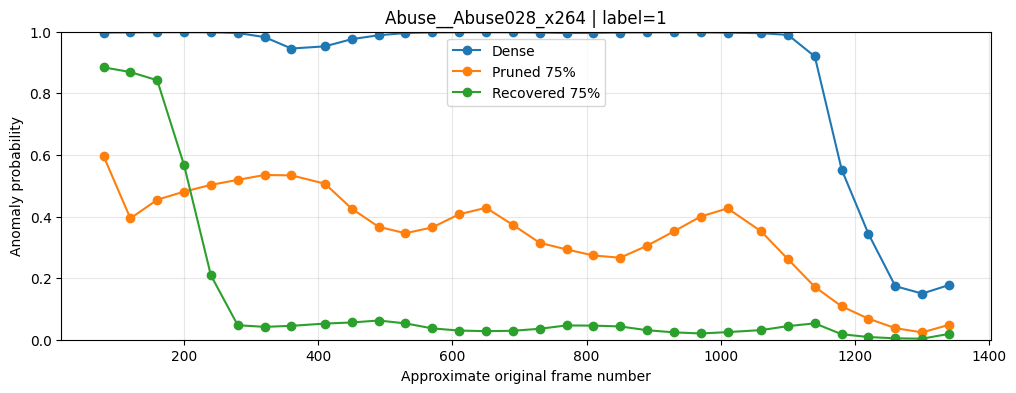

Saved plot data to /content/ucfcrime_videomae_rtfm_small/results/Robbery102_x264_recovered_plot_data.csv


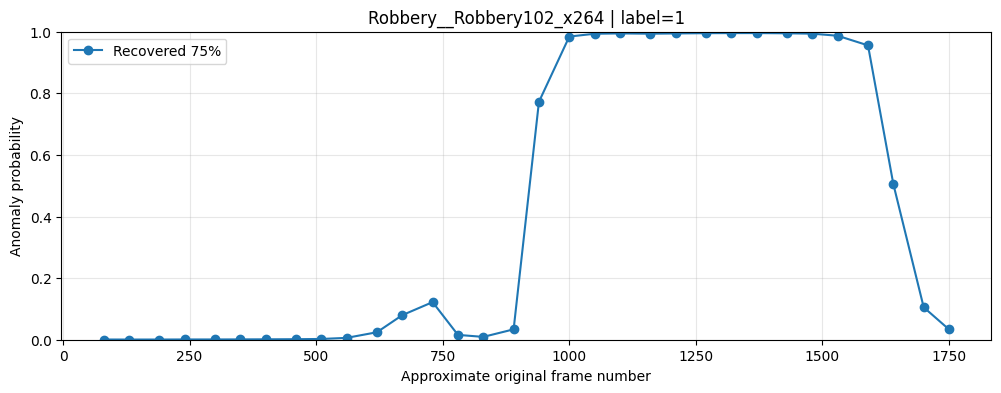

In [ ]:
def plot_model_temporal_comparison(key: str) -> None:
    rows = {
        "Dense": dense_test_predictions[dense_test_predictions["key"] == key].iloc[0],
        f"Pruned {int(CFG.prune_ratio * 100)}%": pruned_test_predictions[pruned_test_predictions["key"] == key].iloc[0],
        f"Recovered {int(CFG.prune_ratio * 100)}%": recovered_test_predictions[recovered_test_predictions["key"] == key].iloc[0],
    }
    centers = rows["Dense"]["snippet_centers_original"]
    plt.figure(figsize=(12, 4))
    for label, row in rows.items():
        plt.plot(centers, row["snippet_probabilities"], marker="o", label=label)
    plt.ylim(0, 1)
    plt.xlabel("Approximate original frame number")
    plt.ylabel("Anomaly probability")
    plt.title(f"{key} | label={rows['Dense']['label']}")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

if len(recovered_test_predictions) > 0:
    example_key = recovered_test_predictions[recovered_test_predictions["label"] == 1].iloc[0]["key"]
    plot_model_temporal_comparison(example_key)

def plot_recovered_only(video_id: str) -> None:
    matching_rows = dense_test_predictions[dense_test_predictions["video_id"] == video_id]
    if matching_rows.empty:
        print(f"Video ID {video_id} not found in the test predictions.")
        return
    row = matching_rows.iloc[0]
    centers = row["snippet_centers_original"]
    probabilities = row["snippet_probabilities"]

    # Save to file
    output_path = RESULT_DIR / f"{video_id}_recovered_plot_data.csv"
    pd.DataFrame({
        "frame_number": centers,
        "anomaly_probability": probabilities
    }).to_csv(output_path, index=False)
    print(f"Saved plot data to {output_path}")

    plt.figure(figsize=(12, 4))
    plt.plot(centers, probabilities, marker="o", label=f"Recovered {int(CFG.prune_ratio * 100)}%")
    plt.ylim(0, 1)
    plt.xlabel("Approximate original frame number")
    plt.ylabel("Anomaly probability")
    plt.title(f"{row['key']} | label={row['label']}")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

plot_recovered_only("Robbery102_x264")


In [ ]:
# from matplotlib.animation import FuncAnimation
# from IPython.display import HTML
# import numpy as np

# def animate_plot_recovered_only(video_id: str, assumed_fps: int = 30) -> None:
#     matching_rows = dense_test_predictions[dense_test_predictions["video_id"] == video_id]
#     if matching_rows.empty:
#         print(f"Video ID {video_id} not found in the test predictions.")
#         return
#     row = matching_rows.iloc[0]
#     centers = row["snippet_centers_original"]
#     probabilities = row["snippet_probabilities"]

#     fig, ax = plt.subplots(figsize=(12, 4))
#     ax.plot(centers, probabilities, marker="o", label=f"Recovered {int(CFG.prune_ratio * 100)}%")
#     ax.set_ylim(0, 1)
#     ax.set_xlim(0, max(centers) + 50)  # Add a little padding
#     ax.set_xlabel("Approximate original frame number")
#     ax.set_ylabel("Anomaly probability")
#     ax.set_title(f"{row['key']} | label={row['label']}")
#     ax.grid(alpha=0.3)
#     ax.legend()

#     # The sliding playhead
#     playhead = ax.axvline(x=0, color='red', linestyle='-', linewidth=2, alpha=0.8)

#     max_frame = max(centers)
#     # To prevent generating thousands of frames for long videos, we can step by a factor
#     # E.g., showing 10 frames per second of animation time to keep rendering reasonable
#     render_fps = 15
#     frame_step = assumed_fps // render_fps if assumed_fps > render_fps else 1
#     frames_to_render = np.arange(0, max_frame + frame_step, frame_step)

#     def update(frame):
#         playhead.set_xdata([frame])
#         return [playhead]

#     ani = FuncAnimation(
#         fig,
#         update,
#         frames=frames_to_render,
#         interval=1000 / render_fps,  # interval in ms
#         blit=True
#     )

#     plt.close(fig)  # Prevent static plot from showing
#     print("Rendering animation... (this may take a minute for long videos)")
#     display(HTML(ani.to_jshtml()))

# animate_plot_recovered_only("Robbery102_x264")

## 23. Save predictions and final experiment summary

In [ ]:
dense_val_predictions.to_pickle(RESULT_DIR / "dense_val_predictions.pkl")
dense_test_predictions.to_pickle(RESULT_DIR / "dense_test_predictions.pkl")
pruned_val_predictions.to_pickle(RESULT_DIR / "pruned_val_predictions.pkl")
pruned_test_predictions.to_pickle(RESULT_DIR / "pruned_test_predictions.pkl")
recovered_val_predictions.to_pickle(RESULT_DIR / "recovered_val_predictions.pkl")
recovered_test_predictions.to_pickle(RESULT_DIR / "recovered_test_predictions.pkl")
comparison.to_csv(RESULT_DIR / "accuracy_comparison.csv", index=False)

summary = {
    "backbone": CFG.videomae_model,
    "rtfm_head": True,
    "importance_method": CFG.importance_method,
    "prune_ratio": CFG.prune_ratio,
    "recovery_fine_tuning": True,
    "dense_test": dense_test_metrics,
    "pruned_test": pruned_test_metrics,
    "recovered_test": recovered_test_metrics,
    "parameter_reduction_percent": 100 * (
        1 - (parameter_count(benchmark_pruned_backbone) + parameter_count(benchmark_pruned_head))
        / (parameter_count(dense_backbone) + parameter_count(dense_head))
    ),
    "efficiency_csv": str(RESULT_DIR / "efficiency_comparison.csv"),
}
print(json.dumps(summary, indent=2, default=str))

{
  "backbone": "MCG-NJU/videomae-small-finetuned-kinetics",
  "rtfm_head": true,
  "importance_method": "taylor",
  "prune_ratio": 0.75,
  "recovery_fine_tuning": true,
  "dense_test": {
    "threshold": 0.47928375005722046,
    "f1": 0.8014705882352942,
    "precision": 0.8257575757575758,
    "recall": 0.7785714285714286,
    "roc_auc": 0.8961904761904761,
    "average_precision": 0.8991952532379215
  },
  "pruned_test": {
    "threshold": 0.002506253309547901,
    "f1": 0.6460807600950119,
    "precision": 0.48398576512455516,
    "recall": 0.9714285714285714,
    "roc_auc": 0.563047619047619,
    "average_precision": 0.5717134173656628
  },
  "recovered_test": {
    "threshold": 0.681030809879303,
    "f1": 0.7717041800643086,
    "precision": 0.7017543859649122,
    "recall": 0.8571428571428571,
    "roc_auc": 0.8446666666666666,
    "average_precision": 0.8191531652551404
  },
  "parameter_reduction_percent": 42.873927819683146,
  "efficiency_csv": "/content/ucfcrime_videomae_rt

## Experimental interpretation

The primary comparison is:

**Dense → Pruned → Pruned + Recovery**

The experiment should be interpreted as three related questions:

1. How much performance is lost when VideoMAE-Small MLP neurons are structurally removed?
2. How much model size and inference cost are reduced by the pruning?
3. How much of the lost performance can be recovered by fine-tuning the compressed model?

Report the dense model as the control, the directly pruned model as the immediate compression result, and the recovered model as the post-pruning adaptation result.